(3394, 5) (10493, 7) (749, 6)
['id', 'title', 'author', 'genre', 'publisher', 'year']
    unit_price  price_in_usd
27      €22¢25         26.70
98      29€50¢         35.40
127     $20¢25         20.25
151     46$99¢         46.99
153     71$50¢         71.50
     unit_price  price_in_usd
1399    $ 61.75         61.75
7892   22.5 USD         22.50
6736    USD38.5         38.50
3234     $23.75         23.75
4687    USD 51.         51.00
3679    55. USD         55.00
7482   50.50EUR         60.60
839   USD 54.75         54.75
unparsed: 0
no-date rows: 0
range: 2024-11-26 23:53:00 -> 2026-09-24 08:31:33
               timestamp                  ts
29   10.12.2025 10:59:59 2025-12-10 10:59:59
101   4.05.2026 11:45:45 2026-05-04 11:45:45
149  30.06.2025 11:49:49 2025-06-30 11:49:49
189  27.01.2026 01:00:00 2026-01-27 01:00:00
196  06.11.2025 01:34:34 2025-11-06 01:34:34
before: 10493
after: 10493
id                 0
user_id            0
book_id            0
quantity           0
unit_price 

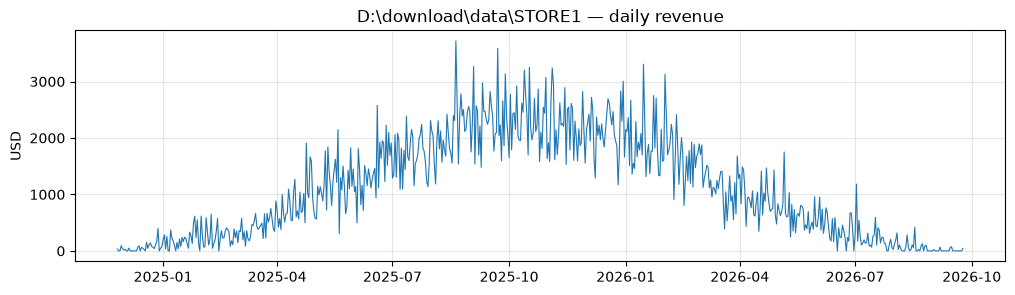

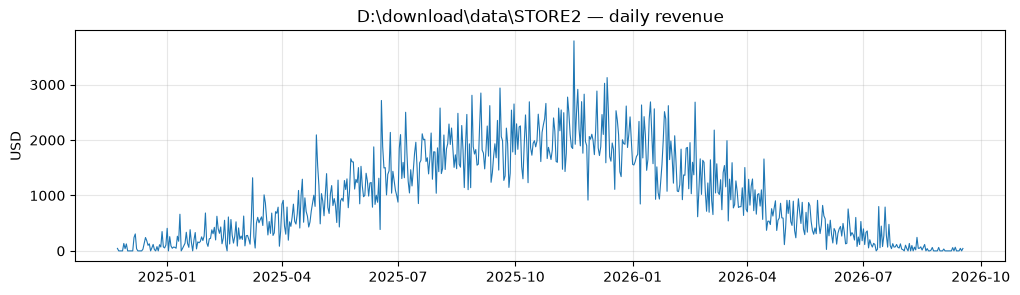

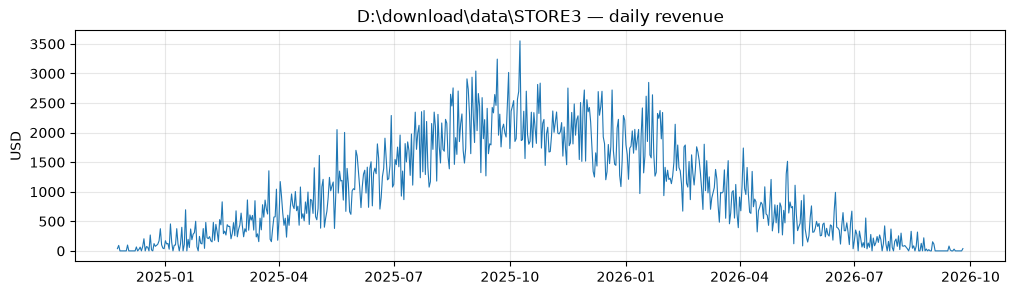

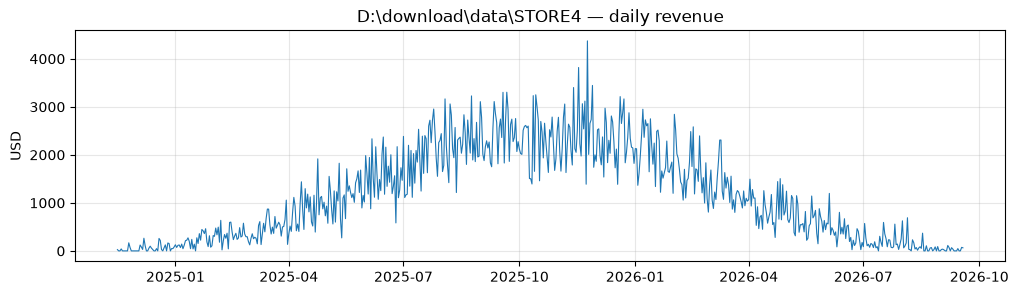

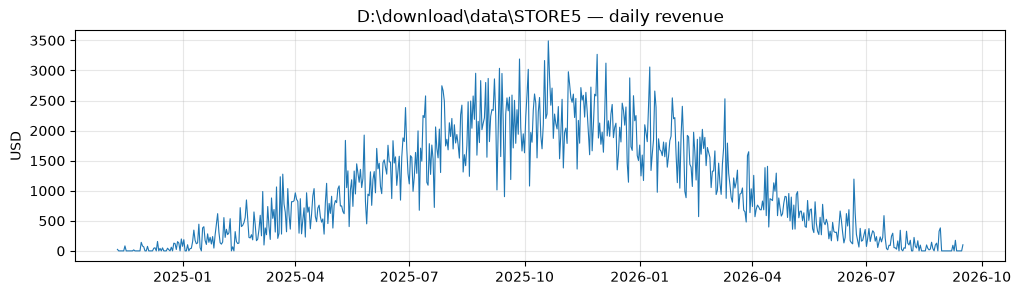

In [ ]:
import re
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from dateutil import parser
stores = [r"D:\download\data\STORE1", r"D:\download\data\STORE2", r"D:\download\data\STORE3", r"D:\download\data\STORE4", r"D:\download\data\STORE5"]

def load(store):

     us = pd.read_csv(store + r"\users.csv", dtype=str, keep_default_na=False)

     us["id"] = us["id"].astype(int)

     orr = pd.read_parquet(store + r"\orders.parquet")

     with open(store + r"\books.yaml", encoding="utf-8") as f:

          bo = pd.DataFrame(yaml.safe_load(f))

     bo.columns = [c.replace(":", "") for c in bo.columns] 

     return us, orr, bo

  
  

S1_us, S1_or, S1_bo = load(r"D:\download\data\STORE1")


def price_to_usd(prices):

     s = []

     for i in prices:

          m = re.search(r"(\d+)(?:[.¢€$]+(\d+))?", i)

          if m.group(2):

               num = float(m.group(1) + "." + m.group(2))

          else:

               num = float(m.group(1))

          if "€" in i or "EUR" in i.upper():

               num *= 1.2

          s.append(num)

     return s

  
  

S1_or["price_in_usd"] = price_to_usd(S1_or["unit_price"])

S1_or["paid_price"] = (S1_or["quantity"] * S1_or["price_in_usd"]).round(2)

  



SENTINEL = datetime(1900, 1, 1)

  
  

def parse_time(stamps):

     time_norm = []

     for i in stamps:

          clean = re.sub(r"\b([AaPp])\.?[Mm]\.?", lambda m: m.group(1).upper() + "M", i)

          clean = re.sub(r"[;,]", " ", clean).strip()

          dayfirst = re.search(r"\b\d{1,2}\.\d{1,2}\.\d{4}\b", clean) is not None

          time_norm.append(parser.parse(clean, default=SENTINEL, dayfirst=dayfirst))

     return pd.to_datetime(time_norm)

  
  

S1_or["ts"] = parse_time(S1_or["timestamp"])

S1_or["date"] = S1_or["ts"].dt.normalize()

S1_or["year"] = S1_or["ts"].dt.year

S1_or["month"] = S1_or["ts"].dt.month

S1_or["day"] = S1_or["ts"].dt.day

  


def clean_orders(orr):

     orr = orr.drop_duplicates()

     orr = orr.drop_duplicates(subset="id")

     orr["shipping"] = orr["shipping"].str.strip().replace({"": pd.NA, "NULL": pd.NA})

     return orr
     

S1_or = clean_orders(S1_or)



def daily_rev(orr):
     daily = orr.groupby("date")["paid_price"].sum().sort_index()
     daily = daily.asfreq("D", fill_value=0)     
     return daily.round(2)  

daily_revenue = daily_rev(S1_or)
top5 = daily_revenue.nlargest(5)
print(top5)
print(daily_revenue.tail(5))
print("check:", round(daily_revenue.sum(), 2), round(S1_or["paid_price"].sum(), 2))

def clean_users(us):

     us["name"] = us["name"].str.strip().str.replace(r"\s+", " ", regex=True)

     us["address"] = (us["address"].str.strip().str.lower()

                         .str.replace(r"\s+", " ", regex=True)

                         .replace({"": pd.NA, "null": pd.NA}))

     us["phone"] = us["phone"].str.replace(r"\D", "", regex=True)

     us["email"] = us["email"].str.strip().str.lower()

     return us

  
  

def find_persons(us):

     fields = ["name", "address", "phone", "email"]

     us["person"] = us["id"]

     while True:

          before = us["person"].copy()

          for f in fields:

               others = [x for x in fields if x != f]

               us["person"] = us.groupby(others, dropna=False)["person"].transform("min")

          if us["person"].equals(before):

               break

     return us

  
  

S1_us = find_persons(clean_users(S1_us))

print("real users:", S1_us["person"].nunique())

print(S1_us["person"].value_counts().value_counts().sort_index())

def author_sets(bo):

     sets = []

     for i in bo["author"]:

          names = [x.strip() for x in i.split(",")]

          sets.append(frozenset(names))

     bo["author_set"] = sets

     return bo

  
  

S1_bo = author_sets(S1_bo)

print("unique author sets:", S1_bo["author_set"].nunique())

  

S1_or["author_set"] = S1_or["book_id"].map(S1_bo.set_index("id")["author_set"])

sold = S1_or.groupby("author_set")["quantity"].sum()

print("most popular:", sorted(sold.idxmax()), "-", sold.max(), "books")

S1_or["person"] = S1_or["user_id"].map(S1_us.set_index("id")["person"])

print("unmatched orders:", S1_or["person"].isna().sum())

  

spend = S1_or.groupby("person")["paid_price"].sum()

top = spend.idxmax()

print("top customer ids:", sorted(S1_us.loc[S1_us["person"] == top, "id"]), "-", round(spend.max(), 2), "$")

print(S1_us[S1_us["person"] == top])

def solve(store):

     us, orr, bo = load(store)

  

     orr["price_in_usd"] = price_to_usd(orr["unit_price"])

     orr["paid_price"] = (orr["quantity"] * orr["price_in_usd"]).round(2)

     orr["ts"] = parse_time(orr["timestamp"])

     orr["date"] = orr["ts"].dt.normalize()

     orr = clean_orders(orr)

  

     us = find_persons(clean_users(us))

     bo = author_sets(bo)

  

     orr["person"] = orr["user_id"].map(us.set_index("id")["person"])

     orr["author_set"] = orr["book_id"].map(bo.set_index("id")["author_set"])

  

     daily = daily_rev(orr)

     sold = orr.groupby("author_set")["quantity"].sum()

     spend = orr.groupby("person")["paid_price"].sum()

     top = spend.idxmax()

  

     return {

          "top5_days": [d.strftime("%Y-%m-%d") for d in daily.nlargest(5).index],

          "unique_users": us["person"].nunique(),

          "author_sets": bo["author_set"].nunique(),

          "top_authors": sorted(sold.idxmax()),

          "best_buyer_ids": sorted(us.loc[us["person"] == top, "id"].tolist()),

          "daily": daily,

     }

  
  

results = {}

for store in stores:

     results[store] = solve(store)

     r = results[store]

     print(store)

     print("  top 5 days:   ", r["top5_days"])

     print("  unique users: ", r["unique_users"])

     print("  author sets:  ", r["author_sets"])

     print("  top authors:  ", r["top_authors"])

     print("  best buyer:   ", r["best_buyer_ids"])
     
for store in stores:

     plt.figure(figsize=(12, 3))

     plt.plot(results[store]["daily"].index, results[store]["daily"].values, linewidth=0.8)

     plt.title(store + " — daily revenue")

     plt.ylabel("USD")

     plt.grid(alpha=0.3)

     plt.show()